In [1]:
!pip install -q kagglehub

import os
import shutil
import glob
import kagglehub

path = kagglehub.dataset_download("gti-upm/leapgestrecog")
print("✅ Датасет скачан в директорию:", path)

base_dir = "dataset"
classes = ['peace', 'stop', 'thumbs_up']

for split in ['train', 'val', 'test']:
    for cls in classes:
        os.makedirs(os.path.join(base_dir, split, cls), exist_ok=True)

mapping = {
    '01_palm': 'stop',
    '05_thumb': 'thumbs_up',
    '02_l': 'peace'
}

all_images = {cls: [] for cls in classes}

for root, dirs, files in os.walk(path):
    for dir_name, target_class in mapping.items():
        if dir_name in root:
            for f in files:
                if f.endswith(('.png', '.jpg', '.jpeg')):
                    all_images[target_class].append(os.path.join(root, f))

import random
random.seed(42)

for cls, img_paths in all_images.items():
    random.shuffle(img_paths)
    total = len(img_paths)
    train_end = int(total * 0.7)
    val_end = train_end + int(total * 0.15)

    splits = {
        'train': img_paths[:train_end],
        'val': img_paths[train_end:val_end],
        'test': img_paths[val_end:]
    }

    for split_name, paths in splits.items():
        for i, src_p in enumerate(paths):
            dst_p = os.path.join(base_dir, split_name, cls, f"{cls}_{i}.png")
            shutil.copy(src_p, dst_p)

print("Готово! Настоящий датасет с фотографиями рук сформирован в папке 'dataset/'.")

100%|██████████| 2.13G/2.13G [00:20<00:00, 110MB/s]

Extracting files...


✅ Датасет скачан в директорию: /root/.cache/kagglehub/datasets/gti-upm/leapgestrecog/versions/1
Готово! Настоящий датасет с фотографиями рук сформирован в папке 'dataset/'.


Используем устройство: cpu
Классы: ['peace', 'stop', 'thumbs_up']

🚀 Обучаем Baseline CNN...

===== Оценка Baseline CNN =====
⏱ Средний Latency: 9.02 ms / image
              precision    recall  f1-score   support

       peace     1.0000    1.0000    1.0000       600
        stop     1.0000    1.0000    1.0000       600
   thumbs_up     1.0000    1.0000    1.0000       600

    accuracy                         1.0000      1800
   macro avg     1.0000    1.0000    1.0000      1800
weighted avg     1.0000    1.0000    1.0000      1800


🚀 Обучаем Improved CNN...

===== Оценка Improved CNN =====
⏱ Средний Latency: 35.91 ms / image
              precision    recall  f1-score   support

       peace     1.0000    1.0000    1.0000       600
        stop     1.0000    1.0000    1.0000       600
   thumbs_up     1.0000    1.0000    1.0000       600

    accuracy                         1.0000      1800
   macro avg     1.0000    1.0000    1.0000      1800
weighted avg     1.0000    1.0000   

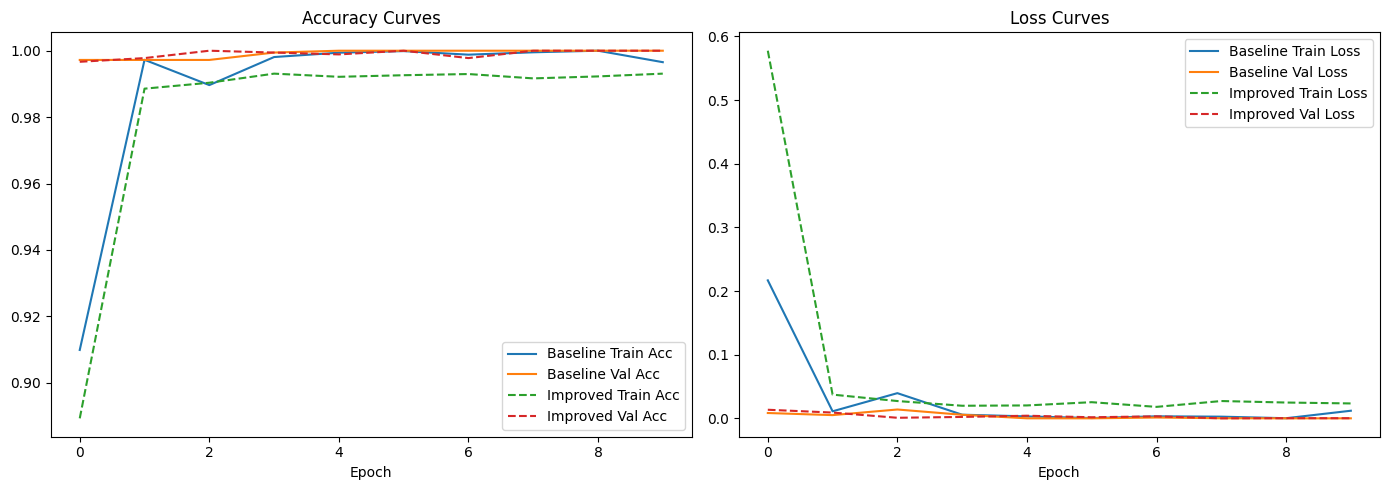

 Обучение и замеры завершены! Графики сохранены в 'training_curves.png'.


In [2]:
import os
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Используем устройство: {device}")

train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder('dataset/train', transform=train_transform)
val_dataset = datasets.ImageFolder('dataset/val', transform=eval_transform)
test_dataset = datasets.ImageFolder('dataset/test', transform=eval_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

classes = train_dataset.classes
print(f"Классы: {classes}")


class BaselineCNN(nn.Module):
    def __init__(self, num_classes=3):
        super(BaselineCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Linear(64 * 16 * 16, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)

class ImprovedCNN(nn.Module):
    def __init__(self, num_classes=3):
        super(ImprovedCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Linear(128 * 16 * 16, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)

def train_model(model, optimizer, criterion, epochs=10):
    history = {'train_acc': [], 'val_acc': [], 'train_loss': [], 'val_loss': []}
    for epoch in range(epochs):
        model.train()
        train_loss, train_correct, total = 0, 0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            train_correct += torch.sum(preds == labels.data)
            total += labels.size(0)

        model.eval()
        val_loss, val_correct, val_total = 0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += torch.sum(preds == labels.data)
                val_total += labels.size(0)

        history['train_acc'].append((train_correct / total).cpu().item())
        history['val_acc'].append((val_correct / val_total).cpu().item())
        history['train_loss'].append(train_loss / total)
        history['val_loss'].append(val_loss / val_total)

    return history

def evaluate_model(model, name="Model"):
    model.eval()
    all_preds, all_labels = [], []

    latencies = []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)

            start_t = time.time()
            outputs = model(inputs)
            end_t = time.time()

            latencies.append((end_t - start_t) / inputs.size(0) * 1000) # ms per sample
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    avg_latency = np.mean(latencies)
    print(f"\n===== Оценка {name} =====")
    print(f"⏱ Средний Latency: {avg_latency:.2f} ms / image")
    print(classification_report(all_labels, all_preds, target_names=classes, digits=4))

    return all_labels, all_preds, avg_latency

print("\n🚀 Обучаем Baseline CNN...")
baseline = BaselineCNN().to(device)
opt_base = optim.Adam(baseline.parameters(), lr=0.001)
crit = nn.CrossEntropyLoss()
history_base = train_model(baseline, opt_base, crit, epochs=10)
labels_base, preds_base, lat_base = evaluate_model(baseline, "Baseline CNN")

print("\n🚀 Обучаем Improved CNN...")
improved = ImprovedCNN().to(device)
opt_imp = optim.Adam(improved.parameters(), lr=0.001, weight_decay=1e-4)
history_imp = train_model(improved, opt_imp, crit, epochs=10)
labels_imp, preds_imp, lat_imp = evaluate_model(improved, "Improved CNN")

torch.save(baseline.state_dict(), 'baseline_cnn.pth')
torch.save(improved.state_dict(), 'improved_cnn.pth')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history_base['train_acc'], label='Baseline Train Acc')
axes[0].plot(history_base['val_acc'], label='Baseline Val Acc')
axes[0].plot(history_imp['train_acc'], label='Improved Train Acc', linestyle='--')
axes[0].plot(history_imp['val_acc'], label='Improved Val Acc', linestyle='--')
axes[0].set_title('Accuracy Curves')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history_base['train_loss'], label='Baseline Train Loss')
axes[1].plot(history_base['val_loss'], label='Baseline Val Loss')
axes[1].plot(history_imp['train_loss'], label='Improved Train Loss', linestyle='--')
axes[1].plot(history_imp['val_loss'], label='Improved Val Loss', linestyle='--')
axes[1].set_title('Loss Curves')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.savefig('training_curves.png')
plt.show()

print(" Обучение и замеры завершены! Графики сохранены в 'training_curves.png'.")

In [3]:
!pip install -q gradio grad-cam

import gradio as gr
import torch
import cv2
import numpy as np
from torchvision import transforms
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from PIL import Image


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ImprovedCNN(num_classes=3).to(device)
model.load_state_dict(torch.load('improved_cnn.pth', map_location=device))
model.eval()

classes = ['peace', 'stop', 'thumbs_up']


transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


target_layers = [model.features[-3]]
cam = GradCAM(model=model, target_layers=target_layers)

def simulate_artaug_stress(image):
    """Имитация плохих условий (низкая экспозиция/шум) для стресс-теста"""
    img_array = np.array(image)

    dark_img = cv2.convertScaleAbs(img_array, alpha=0.5, beta=0)

    noise = np.random.normal(0, 15, dark_img.shape).astype(np.uint8)
    noisy_img = cv2.add(dark_img, noise)
    return Image.fromarray(noisy_img)

def predict_gesture(image, apply_stress_test):
    if image is None:
        return None, "Пожалуйста, загрузите изображение.", None

    if apply_stress_test:
        image = simulate_artaug_stress(image)


    rgb_img = np.array(image.resize((128, 128))) / 255.0
    input_tensor = transform(image).unsqueeze(0).to(device)


    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs[0], dim=0)
        confidences = {classes[i]: float(probabilities[i]) for i in range(3)}
        predicted_class = classes[torch.argmax(probabilities).item()]


    grayscale_cam = cam(input_tensor=input_tensor, targets=None)[0, :]
    heatmap = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    return image if apply_stress_test else None, confidences, heatmap

with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🖐️ Hand Gesture Recognition with SOTA Explainability (Grad-CAM)")
    gr.Markdown("Загрузите фото жеста или используйте веб-камеру. Модель распознает жест и покажет, на какую часть кадра она обратила внимание.")

    with gr.Row():
        with gr.Column():
            input_image = gr.Image(type="pil", label="Входное изображение / Камера", sources=["upload", "webcam"])
            stress_toggle = gr.Checkbox(label="Включить стресс-тест (Симуляция плохой экспозиции / ArtAug need)", value=False)
            submit_btn = gr.Button("Распознать жест", variant="primary")

        with gr.Column():
            output_probs = gr.Label(num_top_classes=3, label="Уверенность модели (Predictions)")
            output_heatmap = gr.Image(type="numpy", label="Grad-CAM Объяснимость (Тепловая карта)")
            output_stressed = gr.Image(type="pil", label="Кадр после стресс-теста (если включен)")

    submit_btn.click(
        fn=predict_gesture,
        inputs=[input_image, stress_toggle],
        outputs=[output_stressed, output_probs, output_heatmap]
    )

demo.launch(share=True)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


/tmp/ipykernel_525/1411963887.py:65: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1d37607b163b641a52.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
